# Практическая работа №1: Pandas — Датасет Video Game Sales
Анализ продаж видеоигр с использованием библиотеки Pandas (Задания 1–15).

### Задание 1. Анализ продаж по платформам

Топ-3 лучших платформ по продажам:
 Platform
PS2     1255.64
X360     979.96
PS3      957.84
Name: Global_Sales, dtype: float64

Худшие 3 платформы по продажам:
 Platform
3DO     0.10
GG      0.04
PCFX    0.03
Name: Global_Sales, dtype: float64

Суммарные продажи по платформам (первые 5):
 Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
Name: Global_Sales, dtype: float64


<string>:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


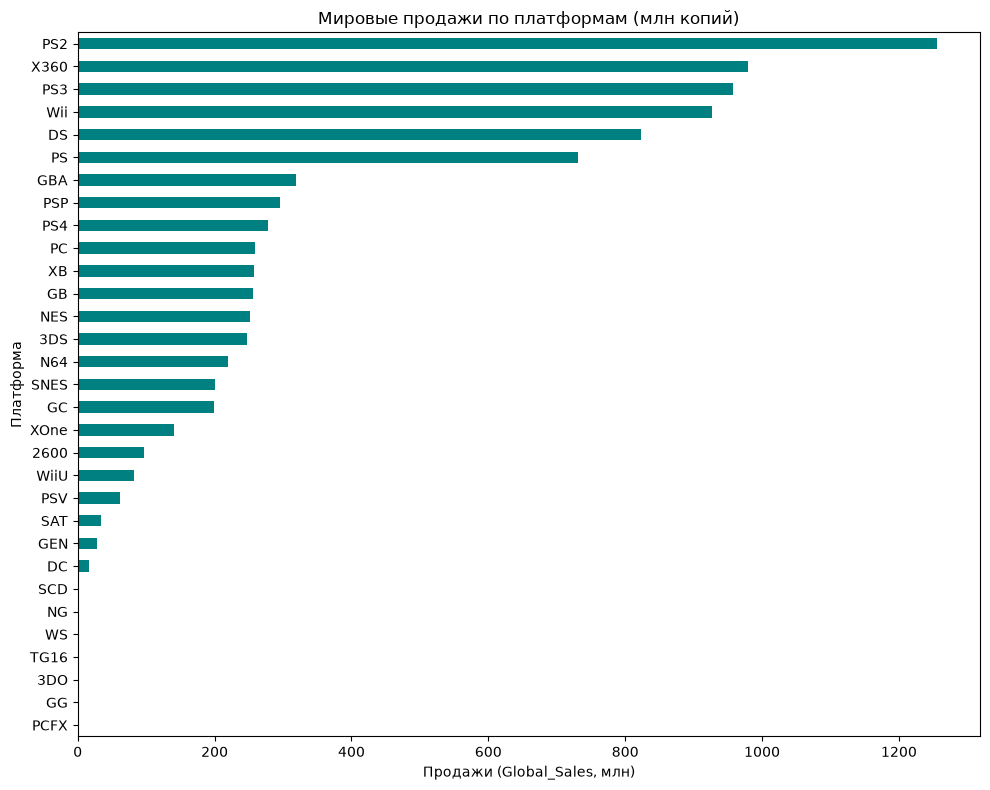

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("outputs", exist_ok=True)

# 1a. Загрузка данных
df_vg = pd.read_csv("vgsales.csv")

# 1b. Исключение пропусков в Global_Sales
df_vg = df_vg.dropna(subset=['Global_Sales'])

# 1c. Продажи по платформам
platform_sales = df_vg.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False)

# 1d. Топ-3 и худшие 3 платформы
print("Топ-3 лучших платформ по продажам:\n", platform_sales.head(3))
print("\nХудшие 3 платформы по продажам:\n", platform_sales.tail(3))

# 1e & 1f. Горизонтальная бар-диаграмма
plt.figure(figsize=(10, 8))
platform_sales.plot(kind='barh', color='teal')
plt.title('Мировые продажи по платформам (млн копий)')
plt.xlabel('Продажи (Global_Sales, млн)')
plt.ylabel('Платформа')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/vgsales_platforms.png", dpi=150)
plt.show()

# 1g. Вывод суммарных продаж в консоль (первые 5)
print("\nСуммарные продажи по платформам (первые 5):\n", platform_sales.head(5))

### Задание 2. Популярные жанры

Суммарные продажи по топ-5 жанрам:
 Genre
Action          1751.18
Sports          1330.93
Shooter         1037.37
Role-Playing     927.37
Platform         831.37
Name: Global_Sales, dtype: float64
Данные экспортированы в outputs/top5_genres.csv


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


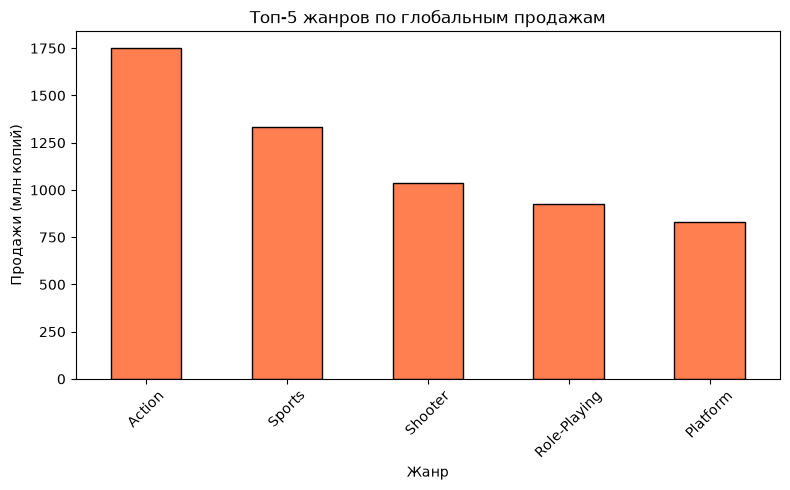

In [ ]:
# 2b & 2c. Продажи по жанрам и топ-5
genre_sales = df_vg.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False)
top5_genres = genre_sales.head(5)

# 2d & 2e. Вертикальная бар-диаграмма
plt.figure(figsize=(8, 5))
top5_genres.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Топ-5 жанров по глобальным продажам')
plt.xlabel('Жанр')
plt.ylabel('Продажи (млн копий)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/vgsales_genres.pdf")
plt.show()

# 2f. Вывод в консоль
print("Суммарные продажи по топ-5 жанрам:\n", top5_genres)

# 2g. Экспорт в CSV
top5_genres.to_csv("outputs/top5_genres.csv", header=True)
print("Данные экспортированы в outputs/top5_genres.csv")

### Задание 3. Продажи по годам

Год с наибольшими продажами: 2008 (678.90 млн)
Год с наименьшими продажами: 1980 (11.38 млн)
Данные экспортированы в outputs/vgsales_years.xlsx


<string>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


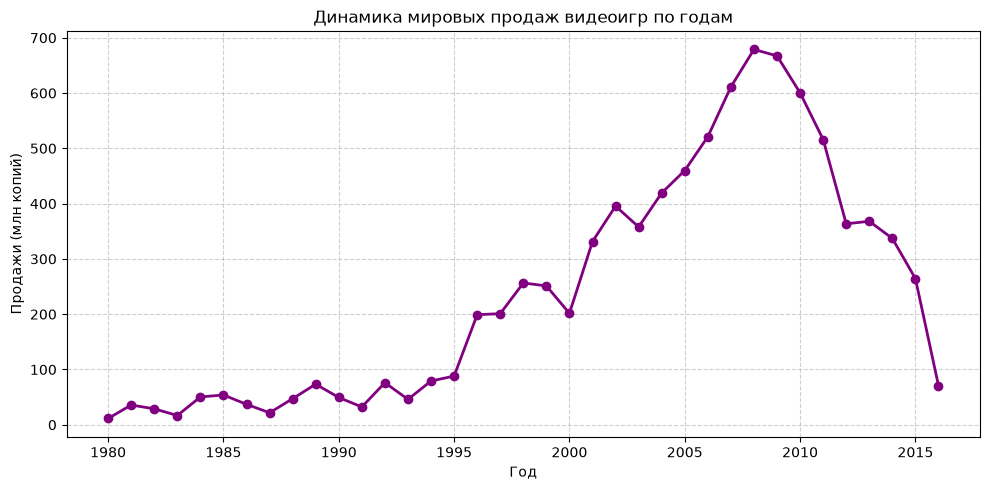

In [ ]:
# 3b. Продажи по годам
df_years = df_vg.dropna(subset=['Year']).copy()
df_years['Year'] = df_years['Year'].astype(int)
year_sales = df_years[df_years['Year'] <= 2016].groupby('Year')['Global_Sales'].sum()

# 3c & 3e. Линия тренда
plt.figure(figsize=(10, 5))
plt.plot(year_sales.index, year_sales.values, marker='o', color='purple', linewidth=2)
plt.title('Динамика мировых продаж видеоигр по годам')
plt.xlabel('Год')
plt.ylabel('Продажи (млн копий)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("outputs/vgsales_years.svg")
plt.show()

# 3d. Годы с максимальными и минимальными продажами
max_year = year_sales.idxmax()
min_year = year_sales.idxmin()
print(f"Год с наибольшими продажами: {max_year} ({year_sales[max_year]:.2f} млн)")
print(f"Год с наименьшими продажами: {min_year} ({year_sales[min_year]:.2f} млн)")

# 3g. Экспорт в Excel
year_sales.to_frame(name='Global_Sales').to_excel("outputs/vgsales_years.xlsx")
print("Данные экспортированы в outputs/vgsales_years.xlsx")

### Задание 4. Региональные предпочтения

Регион с наибольшими продажами: Северная Америка (NA) (4392.95 млн)
Регион с наименьшими продажами: Япония (JP) (1291.02 млн)

Топ игра в NA: Wii Sports
Топ игра в EU: Wii Sports
Топ игра в JP: Pokemon Red/Pokemon Blue
Данные экспортированы в outputs/vgsales_regions.json


<string>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


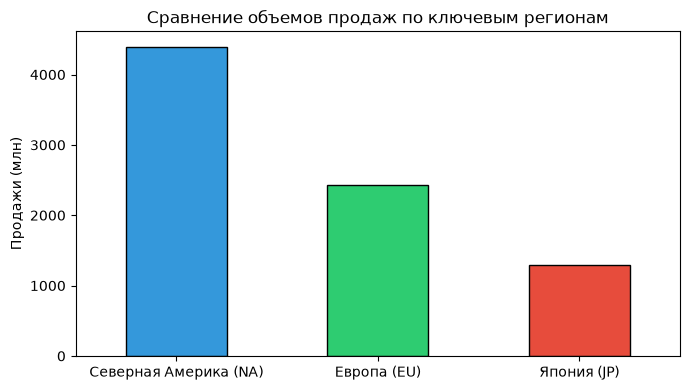

In [ ]:
# 4b. Сравнение продаж по регионам
regions_sum = {
    'Северная Америка (NA)': df_vg['NA_Sales'].sum(),
    'Европа (EU)': df_vg['EU_Sales'].sum(),
    'Япония (JP)': df_vg['JP_Sales'].sum()
}
reg_series = pd.Series(regions_sum)

plt.figure(figsize=(7, 4))
reg_series.plot(kind='bar', color=['#3498db', '#2ecc71', '#e74c3c'], edgecolor='black')
plt.title('Сравнение объемов продаж по ключевым регионам')
plt.ylabel('Продажи (млн)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/vgsales_regions.jpg")
plt.show()

# 4c. Максимальный и минимальный регион
print(f"Регион с наибольшими продажами: {reg_series.idxmax()} ({reg_series.max():.2f} млн)")
print(f"Регион с наименьшими продажами: {reg_series.idxmin()} ({reg_series.min():.2f} млн)")

# 4d. Игры, особенно популярные в конкретных регионах (топ-1 в каждом)
print("\nТоп игра в NA:", df_vg.loc[df_vg['NA_Sales'].idxmax()]['Name'])
print("Топ игра в EU:", df_vg.loc[df_vg['EU_Sales'].idxmax()]['Name'])
print("Топ игра в JP:", df_vg.loc[df_vg['JP_Sales'].idxmax()]['Name'])

# 4g. Экспорт в JSON
reg_series.to_json("outputs/vgsales_regions.json", indent=4)
print("Данные экспортированы в outputs/vgsales_regions.json")

### Задание 5. Самые продаваемые игры

Топ-10 самых продаваемых игр:
    Rank                       Name         Genre Platform  Global_Sales
0     1                 Wii Sports        Sports      Wii         82.74
1     2          Super Mario Bros.      Platform      NES         40.24
2     3             Mario Kart Wii        Racing      Wii         35.82
3     4          Wii Sports Resort        Sports      Wii         33.00
4     5   Pokemon Red/Pokemon Blue  Role-Playing       GB         31.37
5     6                     Tetris        Puzzle       GB         30.26
6     7      New Super Mario Bros.      Platform       DS         30.01
7     8                   Wii Play          Misc      Wii         29.02
8     9  New Super Mario Bros. Wii      Platform      Wii         28.62
9    10                  Duck Hunt       Shooter      NES         28.31
Данные сохранены в outputs/top10_games.html


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


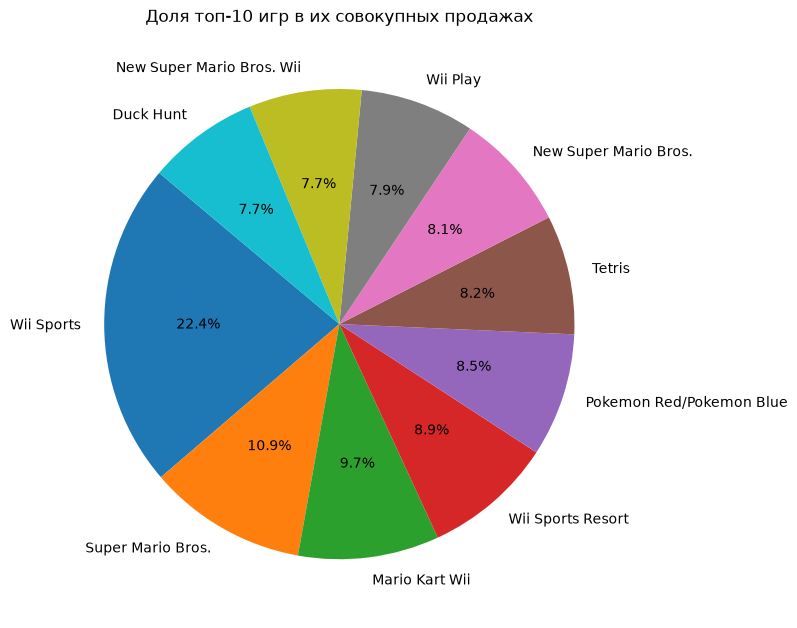

In [ ]:
# 5b & 5c. Сортировка по Global_Sales и топ-10
top10_games = df_vg.sort_values(by='Global_Sales', ascending=False).head(10)
print("Топ-10 самых продаваемых игр:\n", top10_games[['Rank', 'Name', 'Genre', 'Platform', 'Global_Sales']])

# 5d & 5e. Круговая диаграмма
plt.figure(figsize=(8, 8))
plt.pie(top10_games['Global_Sales'], labels=top10_games['Name'], autopct='%1.1f%%', startangle=140)
plt.title('Доля топ-10 игр в их совокупных продажах')
plt.tight_layout()
plt.savefig("outputs/vgsales_top10_games.png", dpi=150)
plt.show()

# 5g. Экспорт в HTML
top10_games[['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Global_Sales']].to_html("outputs/top10_games.html", index=False)
print("Данные сохранены в outputs/top10_games.html")

### Задание 6. Влияние издателя на продажи

Топ-5 издателей по продажам:
 Publisher
Nintendo                       1786.56
Electronic Arts                1110.32
Activision                      727.46
Sony Computer Entertainment     607.50
Ubisoft                         474.72
Name: Global_Sales, dtype: float64
Данные экспортированы в outputs/top5_publishers.csv


<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


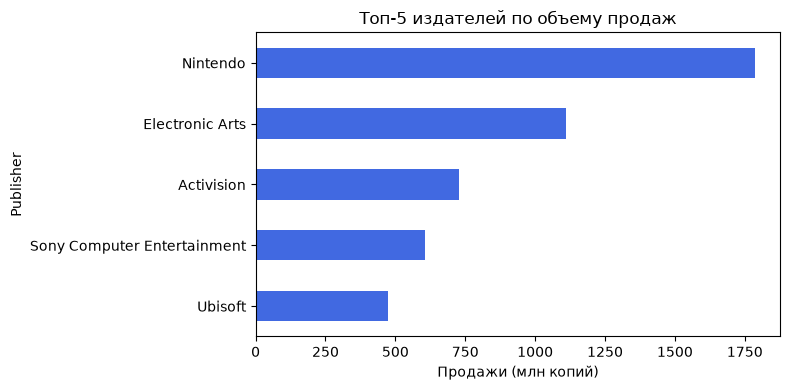

In [ ]:
# 6b & 6c. Группировка по Publisher и топ-5
pub_sales = df_vg.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False).head(5)
print("Топ-5 издателей по продажам:\n", pub_sales)

# 6d & 6e. Горизонтальная бар-диаграмма
plt.figure(figsize=(8, 4))
pub_sales.plot(kind='barh', color='royalblue')
plt.title('Топ-5 издателей по объему продаж')
plt.xlabel('Продажи (млн копий)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/vgsales_publishers.pdf")
plt.show()

# 6g. Экспорт в CSV
pub_sales.to_csv("outputs/top5_publishers.csv", header=True)
print("Данные экспортированы в outputs/top5_publishers.csv")

### Задание 7. Жанры и платформы (Разнообразие и тепловая карта)

Платформа с наибольшим разнообразием жанров: 3DS (12 жанров)
Платформа с наименьшим разнообразием жанров: GG (1 жанров)
Данные сохранены в outputs/genre_platform.xlsx


<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


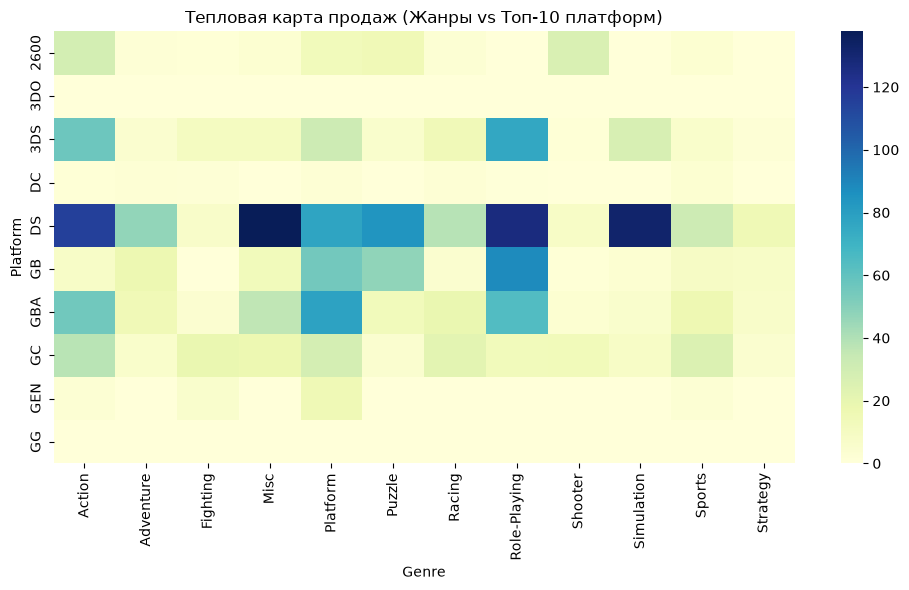

In [ ]:
# 7b. Сводная таблица жанров и платформ
pivot_gp = pd.pivot_table(df_vg, index='Platform', columns='Genre', values='Global_Sales', aggfunc='sum', fill_value=0)

# 7c. Платформа с наибольшим и наименьшим разнообразием (количество уникальных жанров > 0)
genre_counts_per_plat = (pivot_gp > 0).sum(axis=1)
max_div_plat = genre_counts_per_plat.idxmax()
min_div_plat = genre_counts_per_plat.idxmin()
print(f"Платформа с наибольшим разнообразием жанров: {max_div_plat} ({genre_counts_per_plat[max_div_plat]} жанров)")
print(f"Платформа с наименьшим разнообразием жанров: {min_div_plat} ({genre_counts_per_plat[min_div_plat]} жанров)")

# 7d. Тепловая карта для топ-10 платформ
top_plats = df_vg.groupby('Platform')['Global_Sales'].sum().head(10).index
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_gp.loc[top_plats], cmap='YlGnBu')
plt.title('Тепловая карта продаж (Жанры vs Топ-10 платформ)')
plt.tight_layout()
plt.savefig("outputs/genre_platform_heatmap.png", dpi=150)
plt.show()

# 7f. Экспорт в Excel
pivot_gp.to_excel("outputs/genre_platform.xlsx")
print("Данные сохранены в outputs/genre_platform.xlsx")

### Задание 8. Корреляция между продажами и годом выпуска

Коэффициент корреляции Пирсона между годом выпуска и продажами: -0.0746
Данные экспортированы в outputs/corr_sales_year.csv


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


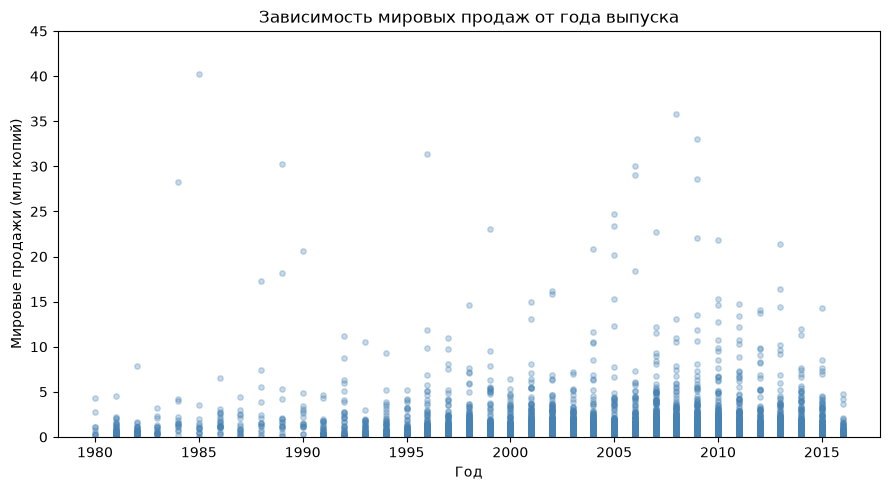

In [ ]:
# 8a & 8b. Диаграмма рассеяния
df_corr = df_vg.dropna(subset=['Year', 'Global_Sales']).copy()
df_corr['Year'] = df_corr['Year'].astype(int)
df_corr = df_corr[df_corr['Year'] <= 2016]

plt.figure(figsize=(9, 5))
plt.scatter(df_corr['Year'], df_corr['Global_Sales'], alpha=0.3, color='steelblue', s=15)
plt.title('Зависимость мировых продаж от года выпуска')
plt.xlabel('Год')
plt.ylabel('Мировые продажи (млн копий)')
plt.ylim(0, 45)
plt.tight_layout()
plt.savefig("outputs/corr_sales_year.svg")
plt.show()

# 8c & 8e. Коэффициент корреляции Пирсона
r_pearson = df_corr['Year'].corr(df_corr['Global_Sales'])
print(f"Коэффициент корреляции Пирсона между годом выпуска и продажами: {r_pearson:.4f}")

# 8f. Экспорт в CSV
df_corr[['Year', 'Global_Sales']].head(500).to_csv("outputs/corr_sales_year.csv", index=False)
print("Данные экспортированы в outputs/corr_sales_year.csv")

### Задание 9. Игры с наибольшими региональными различиями

Топ-10 игр с максимальными региональными расхождениями:

                         Name  NA_Sales  EU_Sales  JP_Sales  Reg_Diff
0                  Wii Sports     41.49     29.02      3.77     37.72
9                   Duck Hunt     26.93      0.63      0.28     26.65
1           Super Mario Bros.     29.08      3.58      6.81     25.50
5                      Tetris     23.20      2.26      4.22     20.94
15         Kinect Adventures!     14.97      4.94      0.24     14.73
3           Wii Sports Resort     15.75     11.01      3.28     12.47
2              Mario Kart Wii     15.85     12.88      3.79     12.06
7                    Wii Play     14.03      9.20      2.93     11.10
8   New Super Mario Bros. Wii     14.59      7.06      4.70      9.89
23         Grand Theft Auto V      9.63      5.31      0.06      9.57
Данные экспортированы в outputs/regional_diff.json


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


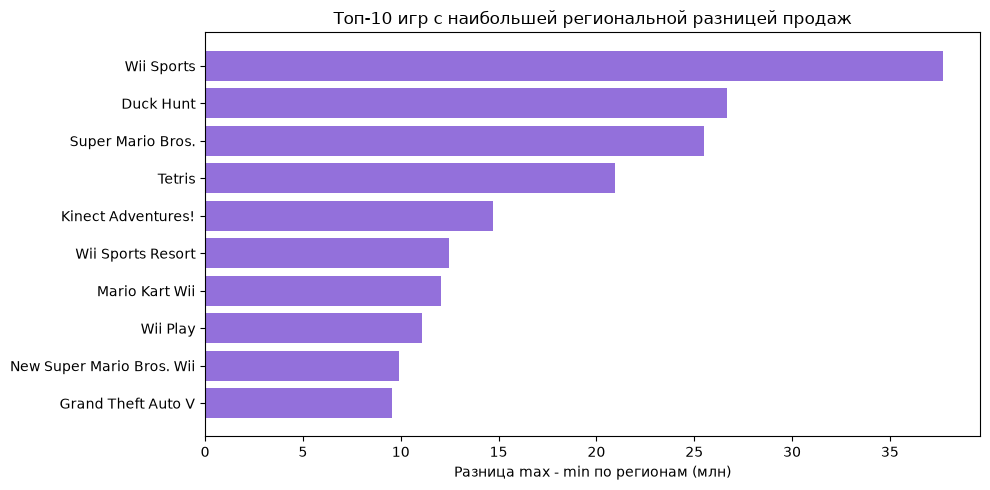

In [ ]:
# 9b. Расчет разности между максимальными и минимальными продажами в регионе
df_vg['Reg_Diff'] = df_vg[['NA_Sales', 'EU_Sales', 'JP_Sales']].max(axis=1) - df_vg[['NA_Sales', 'EU_Sales', 'JP_Sales']].min(axis=1)

# 9c. Топ-10 игр с наибольшими различиями
top10_diff = df_vg.sort_values(by='Reg_Diff', ascending=False).head(10)
print("Топ-10 игр с максимальными региональными расхождениями:\n")
print(top10_diff[['Name', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Reg_Diff']])

# 9d & 9e. Столбчатая диаграмма
plt.figure(figsize=(10, 5))
plt.barh(top10_diff['Name'], top10_diff['Reg_Diff'], color='mediumpurple')
plt.title('Топ-10 игр с наибольшей региональной разницей продаж')
plt.xlabel('Разница max - min по регионам (млн)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/regional_diff_top10.jpg")
plt.show()

# 9g. Экспорт в JSON
top10_diff[['Name', 'Platform', 'Reg_Diff']].to_json("outputs/regional_diff.json", orient='records', indent=4)
print("Данные экспортированы в outputs/regional_diff.json")

### Задание 10. Популярные жанры по годам

Анализ: Жанры Action и Shooter демонстрировали устойчивый рост во второй половине 2000-х, достигнув пиковых продаж в 2008–2011 годах.
Данные экспортированы в outputs/genres_over_years.xlsx


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


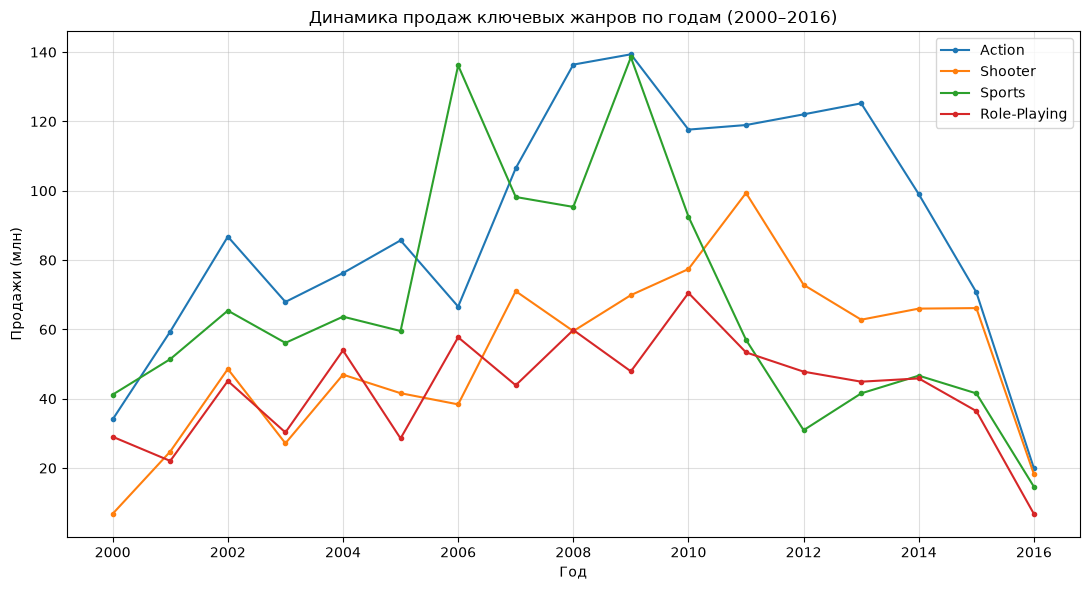

In [ ]:
# 10b. Группировка по жанрам и годам
genre_year = df_years[(df_years['Year'] >= 2000) & (df_years['Year'] <= 2016)].groupby(['Year', 'Genre'])['Global_Sales'].sum().unstack()

# 10c & 10e. График изменения популярности ключевых жанров
plt.figure(figsize=(11, 6))
for g in ['Action', 'Shooter', 'Sports', 'Role-Playing']:
    if g in genre_year.columns:
        plt.plot(genre_year.index, genre_year[g], marker='.', label=g)

plt.title('Динамика продаж ключевых жанров по годам (2000–2016)')
plt.xlabel('Год')
plt.ylabel('Продажи (млн)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("outputs/genres_over_years.png", dpi=150)
plt.show()

# 10d. Вывод
print("Анализ: Жанры Action и Shooter демонстрировали устойчивый рост во второй половине 2000-х, достигнув пиковых продаж в 2008–2011 годах.")

# 10g. Экспорт в Excel
genre_year.to_excel("outputs/genres_over_years.xlsx")
print("Данные экспортированы в outputs/genres_over_years.xlsx")

### Задание 11. Линейная регрессия продаж от года

Коэффициенты линейной регрессии: y = 14.937 * x + -29606.071
Данные экспортированы в outputs/sales_year_reg.csv


<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


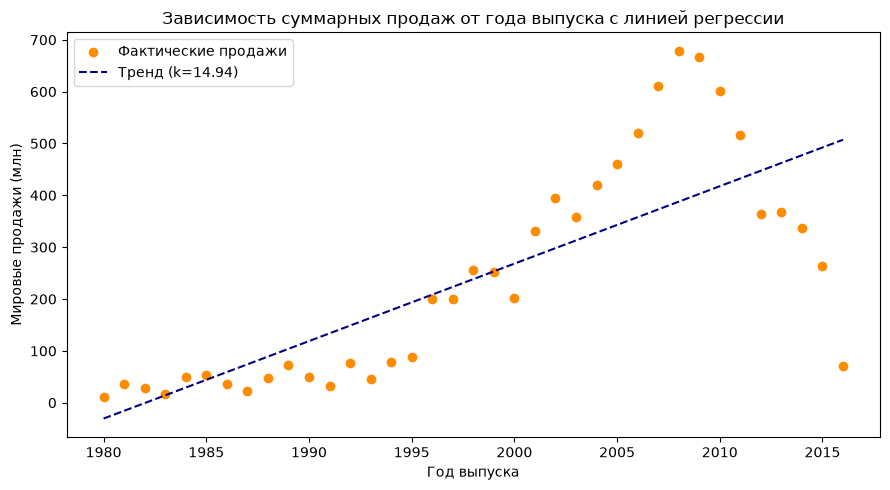

In [ ]:
# 11b & 11c. График зависимости с линией тренда
year_totals = df_years[df_years['Year'] <= 2016].groupby('Year')['Global_Sales'].sum()
x = year_totals.index.values
y = year_totals.values

# 11e. Коэффициенты уравнения линейной регрессии
slope, intercept = np.polyfit(x, y, 1)
print(f"Коэффициенты линейной регрессии: y = {slope:.3f} * x + {intercept:.3f}")

plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='darkorange', label='Фактические продажи')
plt.plot(x, slope * x + intercept, color='navy', linestyle='--', label=f'Тренд (k={slope:.2f})')
plt.title('Зависимость суммарных продаж от года выпуска с линией регрессии')
plt.xlabel('Год выпуска')
plt.ylabel('Мировые продажи (млн)')
plt.legend()
plt.tight_layout()
plt.savefig("outputs/sales_year_regression.png", dpi=150)
plt.show()

# 11f. Экспорт в CSV
pd.DataFrame({'Year': x, 'Sales': y, 'Trend': slope * x + intercept}).to_csv("outputs/sales_year_reg.csv", index=False)
print("Данные экспортированы в outputs/sales_year_reg.csv")

### Задание 12. Диаграмма рассеяния для региональных продаж

Пример координат первых 3 точек: [{'NA_Sales': 41.49, 'EU_Sales': 29.02}, {'NA_Sales': 29.08, 'EU_Sales': 3.58}, {'NA_Sales': 15.85, 'EU_Sales': 12.88}]
Координаты экспортированы в outputs/regional_scatter_coords.json


<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


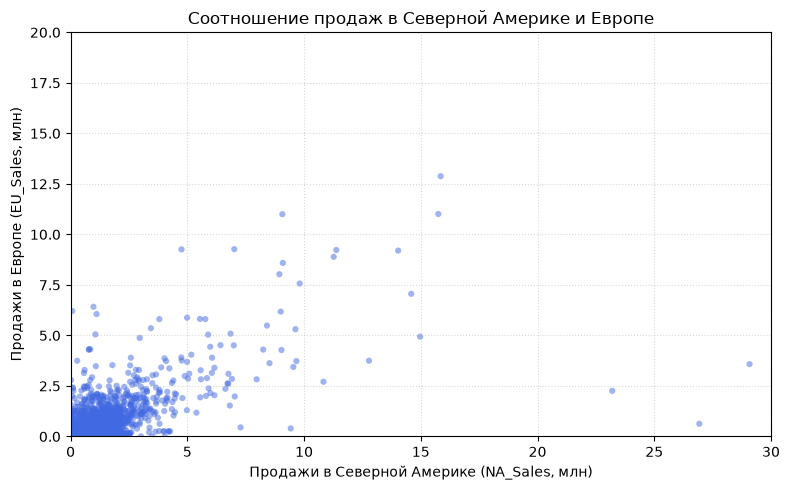

In [ ]:
# 12b & 12c. Рассеяние NA vs EU продаж
plt.figure(figsize=(8, 5))
plt.scatter(df_vg['NA_Sales'], df_vg['EU_Sales'], alpha=0.5, color='royalblue', edgecolor='none', s=20)
plt.title('Соотношение продаж в Северной Америке и Европе')
plt.xlabel('Продажи в Северной Америке (NA_Sales, млн)')
plt.ylabel('Продажи в Европе (EU_Sales, млн)')
plt.xlim(0, 30)
plt.ylim(0, 20)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig("outputs/regional_scatter.svg")
plt.show()

# 12e & 12f. Координаты точек в JSON
sample_coords = df_vg[['NA_Sales', 'EU_Sales']].head(50).to_dict(orient='records')
print("Пример координат первых 3 точек:", sample_coords[:3])
df_vg[['Name', 'NA_Sales', 'EU_Sales']].head(100).to_json("outputs/regional_scatter_coords.json", indent=4)
print("Координаты экспортированы в outputs/regional_scatter_coords.json")

### Задание 13. Детальная тепловая карта жанров и платформ

Данные экспортированы в outputs/platform_genre_detailed.xlsx


<string>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


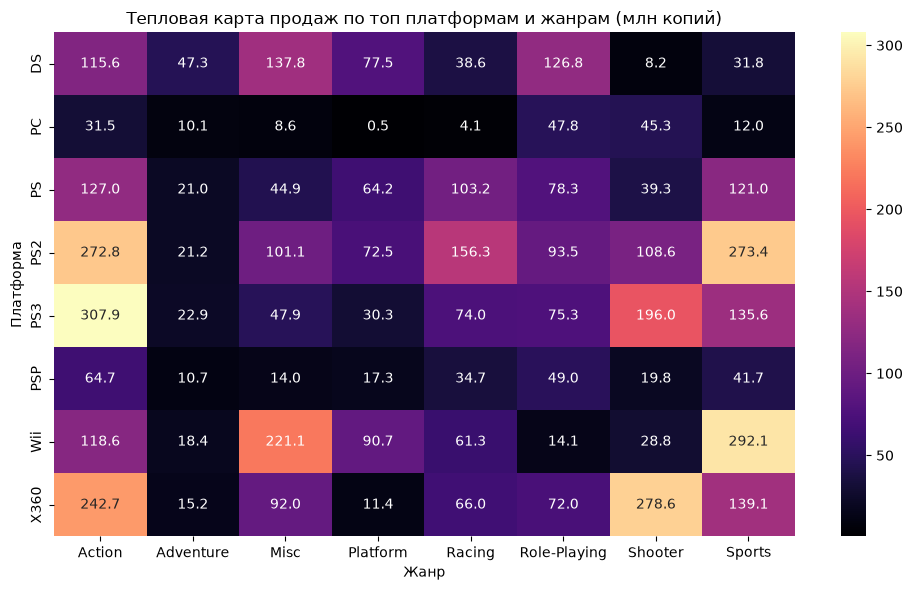

In [ ]:
# 13b & 13c. Полноценная тепловая карта с подписями и цветовой шкалой
top_platforms = df_vg['Platform'].value_counts().head(8).index
top_genres = df_vg['Genre'].value_counts().head(8).index
sub_pivot = pd.pivot_table(
    df_vg[(df_vg['Platform'].isin(top_platforms)) & (df_vg['Genre'].isin(top_genres))],
    index='Platform', columns='Genre', values='Global_Sales', aggfunc='sum', fill_value=0
)

plt.figure(figsize=(10, 6))
sns.heatmap(sub_pivot, annot=True, fmt='.1f', cmap='magma', cbar=True)
plt.title('Тепловая карта продаж по топ платформам и жанрам (млн копий)')
plt.xlabel('Жанр')
plt.ylabel('Платформа')
plt.tight_layout()
plt.savefig("outputs/platform_genre_heatmap_detailed.png", dpi=150)
plt.show()

# 13f. Экспорт в Excel
sub_pivot.to_excel("outputs/platform_genre_detailed.xlsx")
print("Данные экспортированы в outputs/platform_genre_detailed.xlsx")

### Задание 14. Фильтрация игр после 2010 года и популярность жанров

Суммарные продажи жанров после 2010 года:
 Genre
Action          555.86
Shooter         385.39
Role-Playing    235.20
Sports          232.27
Misc            141.19
Name: Global_Sales, dtype: float64
Данные сохранены в outputs/after_2010_genres.csv


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


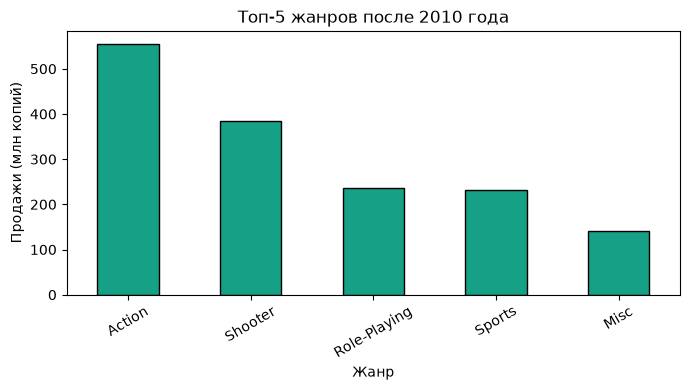

In [ ]:
# 14b & 14c. Игры после 2010 года и топ-5 жанров
df_post_2010 = df_vg[df_vg['Year'] > 2010]
genres_post_2010 = df_post_2010.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False).head(5)

# 14d & 14e. Вертикальная бар-диаграмма
plt.figure(figsize=(7, 4))
genres_post_2010.plot(kind='bar', color='#16a085', edgecolor='black')
plt.title('Топ-5 жанров после 2010 года')
plt.xlabel('Жанр')
plt.ylabel('Продажи (млн копий)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("outputs/after_2010_genres.pdf")
plt.show()

# 14g. Суммарные продажи в консоль
print("Суммарные продажи жанров после 2010 года:\n", genres_post_2010)

# 14h. Экспорт в CSV
genres_post_2010.to_csv("outputs/after_2010_genres.csv", header=True)
print("Данные сохранены в outputs/after_2010_genres.csv")

### Задание 15. Корреляционный анализ количественных признаков

Корреляционная матрица:
               NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales   Year
NA_Sales         1.000     0.768     0.450        0.635         0.941 -0.091
EU_Sales         0.768     1.000     0.436        0.726         0.903  0.006
JP_Sales         0.450     0.436     1.000        0.290         0.612 -0.169
Other_Sales      0.635     0.726     0.290        1.000         0.748  0.041
Global_Sales     0.941     0.903     0.612        0.748         1.000 -0.075
Year            -0.091     0.006    -0.169        0.041        -0.075  1.000
Корреляционная матрица экспортирована в outputs/vgsales_correlation.xlsx


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


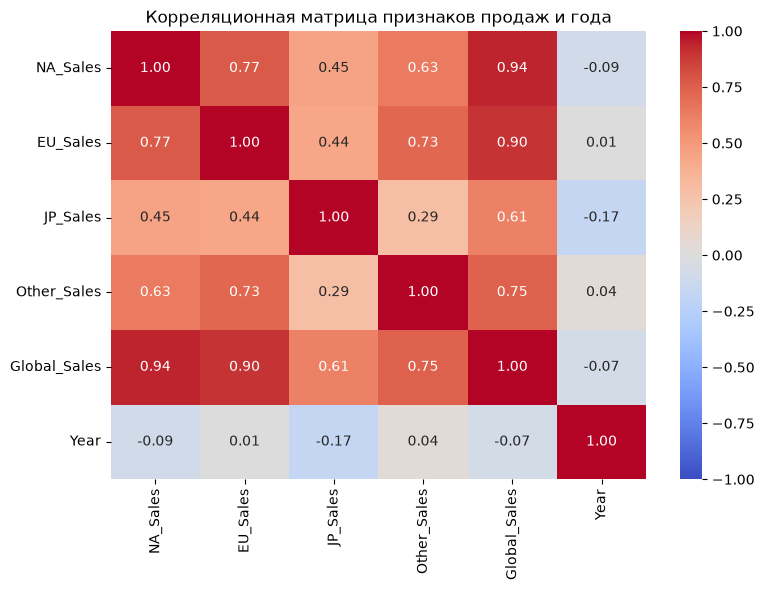

In [ ]:
# 15b. Корреляционная матрица
num_features = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Year']
corr_matrix = df_vg[num_features].corr()

# 15c & 15d. Визуализация тепловой картой
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Корреляционная матрица признаков продаж и года')
plt.tight_layout()
plt.savefig("outputs/vgsales_correlation_matrix.png", dpi=150)
plt.show()

# 15e. Вывод коэффициентов
print("Корреляционная матрица:\n", corr_matrix.round(3))

# 15f. Экспорт в Excel
corr_matrix.to_excel("outputs/vgsales_correlation.xlsx")
print("Корреляционная матрица экспортирована в outputs/vgsales_correlation.xlsx")